# 04 - Analytical datasets and imbalance analysis (Phase 6)
Builds the five analytical tables in `data/analytical/` and `reports/imbalance_analysis.xlsx`. Logic lives in `src/feature_engineering.py`.

Each table is built from facts already aggregated to its grain, so revenue is never double-counted. Customer, product and seller tables are aggregates over history: pass `snapshot_date` to `build_analytical` to rebuild them from data before a cutoff when they feed a predictive model.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 40, 'display.max_colwidth', 90, 'display.max_rows', 80)
from src.cleaning import load_all_processed
from src.feature_engineering import run_feature_engineering, imbalance_distributions, imbalance_chart
from src.validation import validate_analytical
res = run_feature_engineering()
tables, imb = res['tables'], res['imbalance']

## The five analytical tables

In [2]:
pd.DataFrame({k: dict(rows=len(v), columns=v.shape[1]) for k, v in tables.items()}).T

,rows,columns
sales_orders,99441,31
customers,96096,24
products,32951,27
sellers,3095,20
delivery,99441,29


In [3]:
tables['sales_orders'].head(3)

,order_id,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_status,is_delivered,is_canceled_or_unavailable,order_purchase_timestamp,purchase_date,purchase_year,purchase_quarter,purchase_month,purchase_dayofweek,purchase_hour,in_complete_month_window,n_items,n_products,n_sellers,items_value,freight_value,payment_total,n_payment_records,n_payment_types,max_installments,main_payment_type,review_score,has_items,order_value,payment_mismatch
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,03149,sao paulo,SP,delivered,True,False,2017-10-02 10:56:33,2017-10-02,2017,2017Q4,2017-10,0,10,True,1,1,1,29.99,8.72,38.71,3.0,2.0,1.0,voucher,4,True,38.71,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,delivered,True,False,2018-07-24 20:41:37,2018-07-24,2018,2018Q3,2018-07,1,20,True,1,1,1,118.70,22.76,141.46,1.0,1.0,1.0,boleto,4,True,141.46,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,delivered,True,False,2018-08-08 08:38:49,2018-08-08,2018,2018Q3,2018-08,2,8,True,1,1,1,159.90,19.22,179.12,1.0,1.0,3.0,credit_card,5,True,179.12,False


In [4]:
tables['customers'].head(3)

,customer_unique_id,n_orders,n_delivered_orders,first_purchase,last_purchase,total_items,total_payment_value,delivered_payment_value,avg_review_score,n_reviews,customer_zip_code_prefix,customer_city,customer_state,preferred_payment_type,snapshot_date,recency_days,tenure_days,frequency,monetary,avg_order_value,is_repeat_customer,avg_days_between_orders,customer_lat,customer_lng
0,0000366f3b9a7992bf8c76cfdf3221e2,1,1,2018-05-10 10:56:27,2018-05-10 10:56:27,1,141.90,141.90,5.0,1,07787,cajamar,SP,credit_card,2018-10-18,160,0,1,141.90,141.90,False,NaN,-23.337558,-46.828132
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,1,2018-05-07 11:11:27,2018-05-07 11:11:27,1,27.19,27.19,4.0,1,06053,osasco,SP,credit_card,2018-10-18,163,0,1,27.19,27.19,False,NaN,-23.557850,-46.788771
2,0000f46a3911fa3c0805444483337064,1,1,2017-03-10 21:05:03,2017-03-10 21:05:03,1,86.22,86.22,3.0,1,88115,sao jose,SC,credit_card,2018-10-18,586,0,1,86.22,86.22,False,NaN,-27.543700,-48.635335


In [5]:
tables['products'].head(3)

,product_id,product_category_name,product_category_name_english,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,flag_category_missing,flag_physical_attrs_imputed,weight_outlier_iqr,items_sold,n_orders,n_sellers,revenue,freight_total,avg_price,min_price,max_price,first_sale,last_sale,items_sold_delivered,avg_review_score_approx,n_reviewed_orders,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,40,287,1,225.0,16.0,10.0,14.0,False,False,False,1,1,1,10.91,7.39,10.91,10.91,10.91,2018-04-24 16:16:53,2018-04-24 16:16:53,1,5.0,1,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,44,276,1,1000.0,30.0,18.0,20.0,False,False,False,1,1,1,248.00,17.99,248.00,248.00,248.00,2018-01-31 18:55:36,2018-01-31 18:55:36,1,5.0,1,10800.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,46,250,1,154.0,18.0,9.0,15.0,False,False,False,1,1,1,79.80,7.82,79.80,79.80,79.80,2018-07-09 21:18:01,2018-07-09 21:18:01,1,5.0,1,2430.0


In [6]:
tables['sellers'].head(3)

,seller_id,seller_zip_code_prefix,seller_city,seller_state,items_sold,n_orders,n_products,n_categories,revenue,freight_total,avg_price,first_sale,last_sale,active_months,late_shipment_rate,late_delivery_rate,avg_review_score_approx,n_reviewed_orders,seller_lat,seller_lng
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,3,3,3,1,218.70,27.90,72.90,2017-05-05 16:12:29,2017-08-30 11:47:52,2,0.6667,0.3333,3.00,3,-22.893863,-47.062006
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,41,40,30,3,11703.07,1438.73,285.44,2017-03-28 09:00:00,2018-06-06 20:01:45,12,0.0513,0.0513,4.55,40,-22.382922,-46.947670
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,1,1,1,1,158.00,16.21,158.00,2018-07-30 12:20:10,2018-07-30 12:20:10,1,0.0000,0.0000,5.00,1,-22.910174,-43.176775


In [7]:
tables['delivery'].head(3)

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_status_date_conflict,flag_date_sequence_anomaly,is_delivered,approval_hours,handling_days,carrier_days,delivery_days,estimated_days,delay_days,is_late,main_seller_id,main_category,total_weight_g,customer_state,n_items,n_sellers,items_value,freight_value,review_score,seller_state,same_state,distance_km
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,True,0.18,2.37,6.06,8.44,15.54,-7.11,False,3504c0cb71d7fa48d967e0e4c94d59d9,housewares,500.0,SP,1,1,29.99,8.72,4,SP,True,18.7
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,True,30.71,1.74,12.04,13.78,19.14,-5.36,False,289cdb325fb7e7f891c38608bf9e0962,perfumery,400.0,BA,1,1,118.70,22.76,4,SP,False,861.1
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,True,0.28,0.22,9.18,9.39,26.64,-17.25,False,4869f7a5dfa277a7dca6462dcf3b52b2,auto,420.0,GO,1,1,159.90,19.22,5,SP,False,514.6


## Reconciliation of the analytical tables against the cleaned data

In [8]:
validate_analytical()

,table,check,result,detail
0,sales,order_id unique (one row per entity),PASS,99441
1,customer,customer_unique_id unique (one row per entity),PASS,96096
2,product,product_id unique (one row per entity),PASS,32951
3,seller,seller_id unique (one row per entity),PASS,3095
4,delivery,order_id unique (one row per entity),PASS,99441
5,sales,row count = orders,PASS,99441
6,sales,sum(items_value) = item-grain sum(price),PASS,"R$13,591,643.70"
7,sales,sum(freight_value) = item-grain sum(freight),PASS,
8,sales,sum(payment_total) = payment-grain sum(payment_value),PASS,"R$16,008,872.12"
9,customer,row count = distinct customer_unique_id,PASS,


## Imbalance analysis

In [9]:
imb['summary']

,variable,unit,n_classes,total,majority_class,majority_pct,minority_class,minority_pct,imbalance_ratio,classes_below_1pct,normalised_entropy,assessment,interpretation,ml_recommendation
0,order_status,orders,8,99441,delivered,97.02,approved,0.0020,48239.0,6,0.086,natural business imbalance,97% delivered reflects a healthy fulfilment funnel; the other statuses are in-flight o...,Do not balance. For a cancellation model merge to binary (canceled+unavailable vs rest...
1,customer_type,unique customers,2,96096,one-time customer,96.88,repeat customer,3.1188,31.1,0,0.200,natural - genuine retention challenge,"Only ~3% of customers ever return; this is the business finding, not a data defect.",Do not balance. For churn/repeat models use class weights and PR-AUC; build labels wit...
2,review_score,reviews,5,99224,5-star,57.78,2-star,3.1756,18.2,0,0.745,"natural, moderately skewed (J-shaped)","Most customers are satisfied; 1-star is the second largest class, 2-star the rarest.",For satisfaction models prefer binary low (1-2) vs rest with class weights; SMOTENC on...
3,payment_type,payment records,5,103886,credit_card,73.92,not_defined,0.0029,25598.3,1,0.474,natural business imbalance,Credit card dominates Brazilian e-commerce; debit card is rare; 3 'not_defined' rows a...,"Do not balance. As a feature, fold 'not_defined' into 'other'."
4,product_category,items sold,74,112650,bed_bath_table,9.87,security_and_services,0.0018,5557.5,53,0.766,natural long-tail demand,A handful of categories carry most sales; many categories have well under 1% of items.,"Do not balance. For modelling, group categories below ~0.5% share into 'other' or use ..."
5,seller_volume,sellers (by number of orders),6,3095,2-10,42.75,>1000,0.3231,132.3,1,0.767,natural marketplace concentration,Most sellers make a few sales while a small group makes thousands (see concentration s...,Do not balance. Use per-seller minimum-volume thresholds before ranking sellers on rates.
6,customer_state,orders by customer state,27,99441,SP,41.98,RR,0.0463,907.5,15,0.647,natural - follows population and logistics,Sao Paulo alone holds ~42% of customers; northern states are very small.,Do not balance. Aggregate to region for small states; stratify by state when sampling.


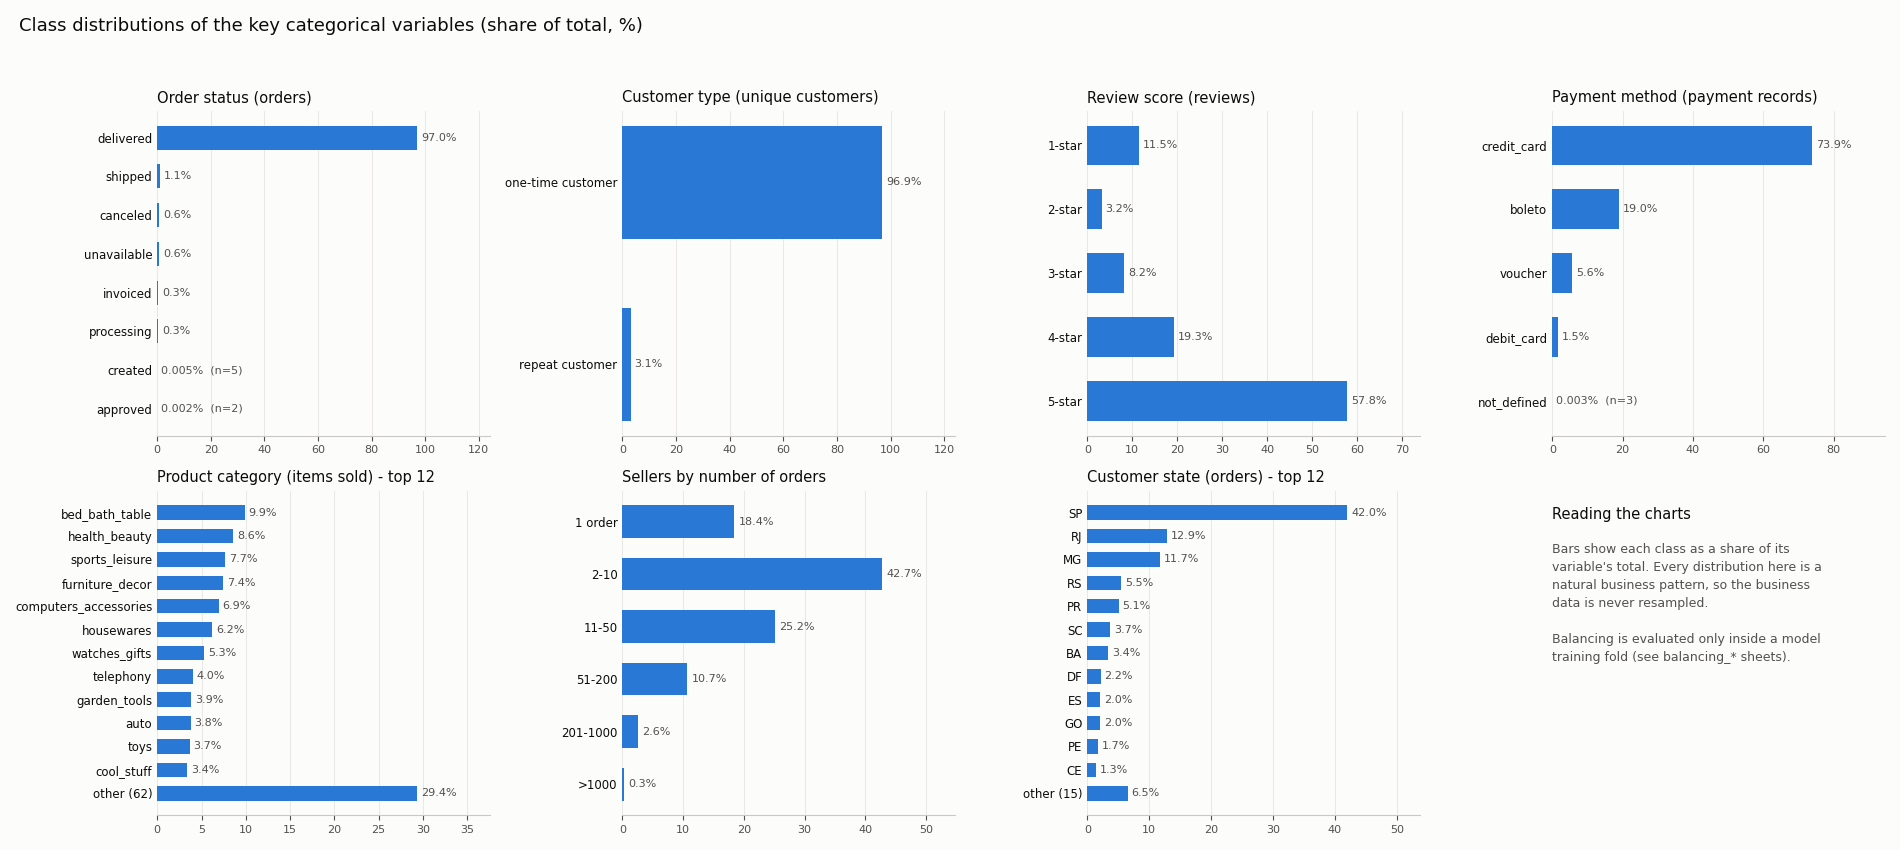

In [10]:
display(Image(imbalance_chart(imbalance_distributions(load_all_processed())).getvalue()))

In [11]:
imb['concentration']

,entity,n_entities,gini,top_1pct_share,top_10pct_share,top_20pct_share,median,max,entities_with_single_unit
0,sellers (GMV),3095,0.792,26.1,67.6,82.7,821.48,229472.63,0
1,sellers (orders),3095,0.786,26.7,68.4,82.9,6.00,1854.00,571
2,products (items sold),32951,0.594,22.1,53.8,67.1,1.00,527.00,18117
3,categories (items sold),74,0.729,9.9,56.0,78.9,279.50,11115.00,0
4,customers (orders),96096,0.033,2.3,13.0,22.7,1.00,17.00,93099
5,customer states (orders),27,0.742,42.0,66.6,80.8,907.00,41746.00,0


## Balancing techniques - evaluated without leakage
Illustrative target: low review (score <= 2) from purchase-time features. The data is split first; encoders, imputers and resamplers see the training fold only; the test fold keeps its original distribution.

In [12]:
imb['balancing_guidance']

,technique,when_appropriate,caveats,verdict_for_olist
0,Stratified sampling,Always - for the train/test split and for cross-validation folds,Keeps the true class ratio in every fold; no data altered,Use by default (or a time-based split for forecasting / churn)
1,Class-weight adjustment,"First choice for imbalanced targets (low review, cancellation, repeat purchase)","No synthetic rows, no information discarded, works with categorical features",Recommended
2,Random undersampling,Very large majority class and training cost matters,Discards real majority data; higher variance,Acceptable on training fold only
3,Random oversampling,"Small data sets, tree models",Duplicates minority rows -> risk of over-fitting,Acceptable on training fold only
4,SMOTE,All-numeric feature spaces,Interpolates between neighbours; meaningless on category codes,Not suitable as-is: Olist features are mixed
5,SMOTENC,Mixed numeric + categorical features,Slower; synthetic rows can blur class boundaries,The appropriate SMOTE variant here - training fold only
6,ADASYN,All-numeric spaces with hard-to-learn minority regions,No categorical variant; amplifies noise near the boundary,Only on one-hot/numeric encodings; generally not preferred


In [13]:
imb['balancing_class_counts']

,technique,train_majority_before,train_minority_before,train_minority_pct_before,train_majority_after,train_minority_after,train_minority_pct_after,test_majority,test_minority,test_minority_pct,test_set_resampled
0,No balancing (baseline),67219,11113,14.19,67219,11113,14.19,16805,2779,14.19,no
1,Class weights,67219,11113,14.19,67219,11113,14.19,16805,2779,14.19,no
2,Random oversampling,67219,11113,14.19,67219,67219,50.00,16805,2779,14.19,no
3,Random undersampling,67219,11113,14.19,11113,11113,50.00,16805,2779,14.19,no
4,SMOTENC (categorical-aware),67219,11113,14.19,67219,67219,50.00,16805,2779,14.19,no
5,ADASYN (on one-hot encoding),67219,11113,14.19,67219,68778,50.57,16805,2779,14.19,no


In [14]:
imb['balancing_metrics']

,technique,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc,true_neg,false_pos,false_neg,true_pos
0,No balancing (baseline),0.4796,0.0169,0.0327,0.5069,0.6368,0.2433,16754.0,51.0,2732.0,47.0
1,Class weights,0.2140,0.4908,0.2980,0.5963,0.6329,0.2380,11795.0,5010.0,1415.0,1364.0
2,Random oversampling,0.2179,0.4807,0.2999,0.5977,0.6326,0.2374,12011.0,4794.0,1443.0,1336.0
3,Random undersampling,0.2057,0.5264,0.2958,0.5951,0.6300,0.2353,11154.0,5651.0,1316.0,1463.0
4,SMOTENC (categorical-aware),0.4181,0.0266,0.0501,0.5102,0.6276,0.2318,16702.0,103.0,2705.0,74.0
5,ADASYN (on one-hot encoding),0.4797,0.0212,0.0407,0.5087,0.6300,0.2384,16741.0,64.0,2720.0,59.0
6,"Target: review score <= 2, purchase-time features only, stratified 80/20 split, thresh...",NaN,NaN,NaN,NaN,NaN,0.1419,NaN,NaN,NaN,NaN
